
# Telco Customer Churn Prediction

## Project Overview

The objective of this project is to develop machine learning models to predict customer churn in the telecommunications industry.

Customer churn refers to customers discontinuing their services with a company.

## Project Objectives

1. Explore and understand the dataset.
2. Perform exploratory data analysis (EDA).
3. Clean and preprocess the data.
4. Engineer relevant features.
5. Develop machine learning models.
6. Evaluate and compare model performance.
7. Identify the factors associated with customer churn.

## Author
Fatemeh Khawari


# Telco Customer Churn Prediction

## Project Roadmap

This project follows seven stages, from understanding the dataset to developing and evaluating machine learning models.

### Project Progress

- [x] **Stage 1 — Data Understanding & Initial Inspection**

  - Understand the dataset structure, rows, columns, variable types, and descriptive statistics.

- [ x] **Stage 2 — Exploratory Data Analysis (EDA)**

  - Explore distributions, patterns, relationships, correlations, and visualize the data.

- [ x] **Stage 3 — Data Cleaning**

  - Handle missing values, duplicates, incorrect data types, inconsistent values, and data-quality issues.

- [ x] **Stage 4 — Feature Engineering & Preprocessing**

  - Prepare variables for machine learning through encoding, scaling, and feature creation.

- [ x] **Stage 5 — Model Training**

  - Train machine learning algorithms, including Logistic Regression and Random Forest.

- [x ] **Stage 6 — Model Evaluation**

  - Evaluate model performance using precision, recall, F1-score, ROC-AUC, and confusion matrices.

- [ x] **Stage 7 — Interpretation & Final Project**

  - Interpret results, identify factors associated with customer churn, document findings, and prepare the final GitHub project.

---

**Current Status:** Stage 1 — Data Understanding & Initial Inspection (Completed)


In [33]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#configure visualization setting
sns.set_theme(style = 'whitegrid')
plt.rcParams['figure.figsize'] = (10 , 6)

#Display a confirmation message
print("Libraries are imported successfully")



Libraries are imported successfully


In [34]:
# URL of the dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

# Load the dataset
df = pd.read_csv(url)

In [35]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [36]:
df.shape

(7043, 21)

In [37]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## Dataset Dictionary & Feature Overview

### Dataset Dimensions
- **Number of observations (rows):** 7,043
- **Number of features (columns):** 20
- **Number of columns including the target variable:** 21
- **Target variable:** `Churn`

### Feature Description

| No. | Column | Meaning | Data Type | Variable Type |
|---:|---|---|---|---|
| 1 | customerID | Unique identifier assigned to each customer | String | Identifier |
| 2 | gender | Customer's gender | String | Categorical – Binary |
| 3 | SeniorCitizen | Whether the customer is a senior citizen (0 = No, 1 = Yes) | Integer | Categorical – Binary |
| 4 | Partner | Whether the customer has a partner | String | Categorical – Binary |
| 5 | Dependents | Whether the customer has dependents | String | Categorical – Binary |
| 6 | tenure | Number of months the customer has stayed with the company | Integer | Numerical – Discrete |
| 7 | PhoneService | Whether the customer has phone service | String | Categorical – Binary |
| 8 | MultipleLines | Whether the customer has multiple phone lines | String | Categorical |
| 9 | InternetService | Type of internet service (DSL, Fiber optic, or No) | String | Categorical – Nominal |
| 10 | OnlineSecurity | Whether the customer has online security service | String | Categorical |
| 11 | OnlineBackup | Whether the customer has online backup service | String | Categorical |
| 12 | DeviceProtection | Whether the customer has device protection | String | Categorical |
| 13 | TechSupport | Whether the customer has technical support | String | Categorical |
| 14 | StreamingTV | Whether the customer has streaming TV service | String | Categorical |
| 15 | StreamingMovies | Whether the customer has streaming movies service | String | Categorical |
| 16 | Contract | Customer's contract type (month-to-month, one year, two year) | String | Categorical – Ordinal-like |
| 17 | PaperlessBilling | Whether the customer uses paperless billing | String | Categorical – Binary |
| 18 | PaymentMethod | Customer's payment method | String | Categorical – Nominal |
| 19 | MonthlyCharges | Monthly amount charged to the customer | Float | Numerical – Continuous |
| 20 | TotalCharges | Total amount charged to the customer | String (to be investigated) | Numerical – Continuous (intended) |
| 21 | Churn | Whether the customer left the company (Yes/No) | String | Target – Binary Categorical |

### Understanding Variable Types

**1. Numerical Variables**

Variables representing quantities that can be measured or counted.

- **Discrete:** Countable values, usually whole numbers. Example: `tenure`.
- **Continuous:** Measurable quantities that can take decimal values. Example: `MonthlyCharges`.

**2. Categorical Variables**

Variables representing groups, labels, or characteristics.

- **Binary:** Exactly two categories. Example: `Partner` (Yes/No).
- **Nominal:** Categories without a natural order. Example: `PaymentMethod`.
- **Ordinal:** Categories with a meaningful order. Example: contract duration (month-to-month, one year, two years).

**3. Identifier**

A value used to distinguish individual observations. Example: `customerID`. It is generally excluded from predictive modeling.

**4. Target Variable**

The variable we want our machine learning model to predict. In this project, the target is `Churn`.

In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [39]:
df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


### Statistical Interpretation of Numerical Variables

#### 1. SeniorCitizen Column

- **Mean:** Approximately 16.21% of customers are senior citizens, while 83.79% are non-senior citizens.
- **Standard deviation:** Approximately 0.37. This measures the dispersion of the binary values (0 and 1) around their mean. The distribution is dominated by category 0 (non-senior citizens).
- **Minimum = 0:** At least one customer is not a senior citizen.
- **Maximum = 1:** At least one customer is a senior citizen.
- **Quartiles (25%, 50%, and 75%) = 0:** At least 75% of customers belong to category 0, meaning they are non-senior citizens.

#### 2. Tenure Column

- **Mean:** The average customer tenure is approximately 32.37 months (2.7 years).
- **Standard deviation:** Approximately 24.56 months, indicating considerable variation in customer tenure. Some customers have recently joined the company, while others have maintained their relationship with the company for several years.
- **Minimum = 0:** At least one customer has a tenure of zero months, indicating a very recently established customer relationship.
- **25th percentile = 9 months:** Approximately 25% of customers have a tenure of 9 months or less.
- **50th percentile (Median) = 29 months:** Half of the customers have a tenure of 29 months or less, while the other half have a tenure of 29 months or more.
- **75th percentile = 55 months:** Approximately 75% of customers have a tenure of 55 months or less.
- **Maximum = 72 months:** The longest customer tenure is 72 months (6 years).

#### 3. MonthlyCharges Column

- **Mean:** The average monthly charge per customer is approximately $64.76.
- **Standard deviation:** Approximately $30.09, indicating considerable variation in monthly charges. Some customers pay relatively low monthly amounts, while others pay substantially more.
- **Minimum = $18.25:** The lowest monthly charge recorded is $18.25.
- **25th percentile = $35.50:** Approximately 25% of customers pay $35.50 or less per month.
- **50th percentile (Median) = $70.35:** Half of the customers pay $70.35 or less, while the other half pay $70.35 or more.
- **75th percentile = $89.85:** Approximately 75% of customers pay $89.85 or less per month.
- **Maximum = $118.75:** The highest monthly charge recorded is $118.75.

In [40]:
df.isnull().sum()
# missing data
# missing data = 0 does not necessarily mena that the data is clean, 
#For example:
#- A column might contain empty strings ("").
#- A numerical column might contain incorrect values.
#- There might be duplicate rows.
#- Some values might have inconsistent formats.

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [41]:
# Check TotalCharge Data type
print("1.TotalCharges data type:")
print(df["TotalCharges"].dtype)

#Check duplicated rows
print("\n2.Number of Duplicated Rows")
print(df.duplicated().sum())

#Check churn distribution
print("\n3.Churn distribution(counts):")
print(df["Churn"].value_counts())
#Check churn distribution
print("\n Churn ditribution(Percentages):")
print(df["Churn"].value_counts(normalize = True)*100)

#Approximately 73.46% of customers stayed with the telecom company.
#Approximately 26.54% of customers left the company.

1.TotalCharges data type:
str

2.Number of Duplicated Rows
0

3.Churn distribution(counts):
Churn
No     5174
Yes    1869
Name: count, dtype: int64

 Churn ditribution(Percentages):
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [42]:
# 1. Check TotalCharges data type
print("TotalCharges Data Type:")
print(df["TotalCharges"].dtype)

# 2. Check duplicate rows
print("\nNumber of Duplicate Rows:")
print(df.duplicated().sum())

TotalCharges Data Type:
str

Number of Duplicate Rows:
0


In [43]:
# Data types of all columns
print("DATA TYPES")
print(df.dtypes)


DATA TYPES
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [44]:
# Number of unique values in each column
print("\nUNIQUE VALUES")
print(df.nunique())



UNIQUE VALUES
customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64


In [45]:
# Missing values
print("MISSING VALUES")
print(df.isnull().sum())

MISSING VALUES
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [46]:
# Duplicate rows
print("DUPLICATE ROWS")
print(df.duplicated().sum())

DUPLICATE ROWS
0


In [47]:
# Categorical variable summaries
print("CATEGORICAL SUMMARY")
print(df.describe(include="str"))

#top means most frequently occuring value
#freq means number of time that most frequent value occurs

CATEGORICAL SUMMARY
        customerID gender Partner Dependents PhoneService MultipleLines  \
count         7043   7043    7043       7043         7043          7043   
unique        7043      2       2          2            2             3   
top     7590-VHVEG   Male      No         No          Yes            No   
freq             1   3555    3641       4933         6361          3390   

       InternetService OnlineSecurity OnlineBackup DeviceProtection  \
count             7043           7043         7043             7043   
unique               3              3            3                3   
top        Fiber optic             No           No               No   
freq              3096           3498         3088             3095   

       TechSupport StreamingTV StreamingMovies        Contract  \
count         7043        7043            7043            7043   
unique           3           3               3               3   
top             No          No              No  Mo

In [48]:
inspection = pd.DataFrame({
    "Data Type" : df.dtypes,
    "Missing Values" : df.isnull().sum(),
    "Unique Values" : df.nunique()
})

inspection

,Data Type,Missing Values,Unique Values
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


# Stage 2 — Exploratory Data Analysis (EDA)

**Objective:**

Explore the dataset to understand customer characteristics, identify patterns and relationships between variables, and investigate factors associated with customer churn using statistical analysis and data visualization.

## Analysis Roadmap

### 2.1 Univariate Analysis
Examine individual variables independently.

- Analyze the distribution of the target variable (`Churn`).
- Explore categorical variables using frequency tables and bar charts.
- Examine numerical variables using histograms, box plots, and descriptive statistics.
- Identify unusual distributions and potential outliers.

### 2.2 Bivariate Analysis
Investigate relationships between two variables.

- Explore the relationship between categorical features and customer churn.
- Examine how numerical features relate to churn.
- Compare customer groups based on their churn status.
- Identify variables that may be associated with customer retention or churn.

### 2.3 Multivariate Analysis
Explore relationships among multiple variables.

- Examine correlations between numerical features.
- Investigate combinations of customer characteristics.
- Identify potentially important patterns involving multiple features.

### 2.4 Key Findings and Insights
Summarize the main discoveries from the analysis.

- Identify customer characteristics associated with higher churn.
- Highlight important patterns and potential risk factors.
- Document observations supported by statistical results and visualizations.

---

**Expected Outcome:**

A comprehensive understanding of customer behavior, variable distributions, and relationships associated with churn. These findings will guide the subsequent data-cleaning, feature-engineering, and machine-learning stages.

In [49]:
#2.1 Univariate analysis
#Count customers in each churn catagory
churn_counts = df["Churn"].value_counts()
#calculate percentage
churn_percentages = df["Churn"].value_counts(normalize = True)*100
#Display results
print("customer churn counts:")
print(churn_counts)

print ("\ncustomer churn percentages:")
print(churn_percentages.round(2))


customer churn counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

customer churn percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [50]:
#Create a bar chart

#Set visualize style
sns.set_theme(style = "whitegrid")

#create figure
plt.figure(figsize=(8,5))

#create a bar chart
ax = sns.countplot(data = df , x = "Churn" , hue = "Churn" , order =["No" , "Yes"] , palette = "Set2" , legend = False)

#Add title and Lables
plt.title("Customers Churn Distribution" , fontsize =15)
plt.xlabel("Customer Churn" , fontsize = 12)
plt.ylabel("Number of Customers" , fontsize = 12)

#Add count label above bar
for container in ax.containers:
    ax.bar_label(container, padding = 3)


plt.tight_layout()
 plt.show()

IndentationError: unexpected indent (2360691270.py, line 23)

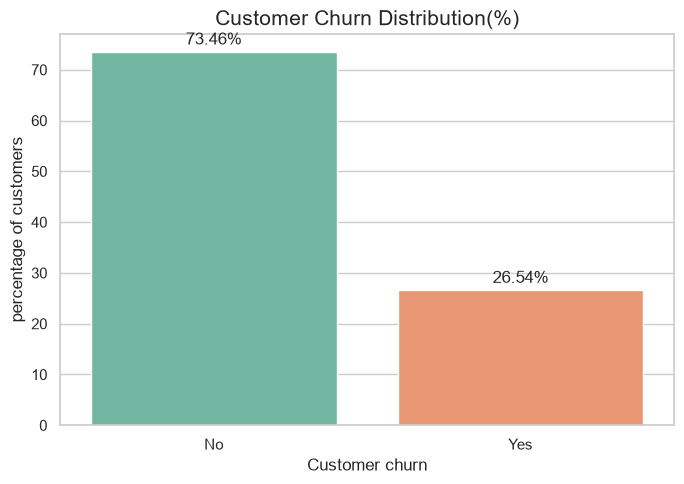

In [51]:
#Create a percentage chart
plt.figure(figsize = (7,5))
ax = sns.barplot(
    x = churn_percentages.index,
    y = churn_percentages.values,
    hue = churn_percentages.index,
    palette = "Set2",
    legend = False
)

plt.title("Customer Churn Distribution(%)" , fontsize = 15)
plt.xlabel("Customer churn" , fontsize = 12)
plt.ylabel("percentage of customers" , fontsize = 12)

for container in ax.containers:
    ax.bar_label(container , fmt = "%.2f%%", padding = 3)

plt.tight_layout()
plt.show()

In [52]:
#identify categorical columns
categorical_columns = df.select_dtypes(include = ["object" , "str"]).columns

#Display frequency distributions and percentages
for column in categorical_columns:
    print(f"{'=' * 50}")
    print(f"Feature:{column}")
    print(f"{'=' * 50}")

    #calculate frequency
    counts = df[column].value_counts()

    #calculate percentages
    percentages = df[column].value_counts(normalize = True) * 100

    #combine results in one table
    summary =pd.DataFrame({
        " Frequency" : counts,
        "Percentage(%)" :percentages.round(2)
    })

    print(summary)

Feature:customerID
             Frequency  Percentage(%)
customerID                           
7590-VHVEG           1           0.01
5575-GNVDE           1           0.01
3668-QPYBK           1           0.01
7795-CFOCW           1           0.01
9237-HQITU           1           0.01
...                ...            ...
6840-RESVB           1           0.01
2234-XADUH           1           0.01
4801-JZAZL           1           0.01
8361-LTMKD           1           0.01
3186-AJIEK           1           0.01

[7043 rows x 2 columns]
Feature:gender
         Frequency  Percentage(%)
gender                           
Male          3555          50.48
Female        3488          49.52
Feature:Partner
          Frequency  Percentage(%)
Partner                           
No             3641           51.7
Yes            3402           48.3
Feature:Dependents
             Frequency  Percentage(%)
Dependents                           
No                4933          70.04
Yes               2110

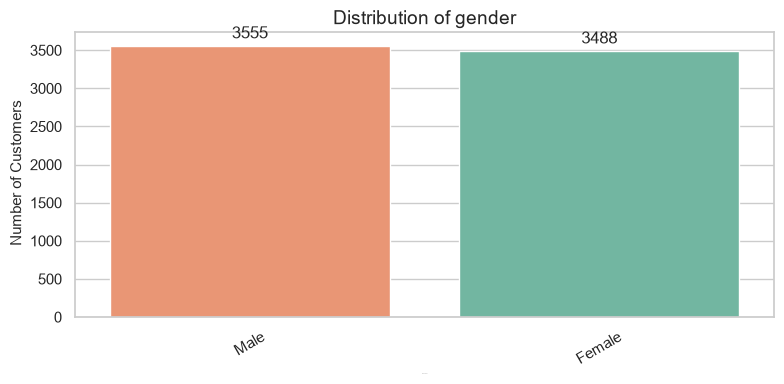

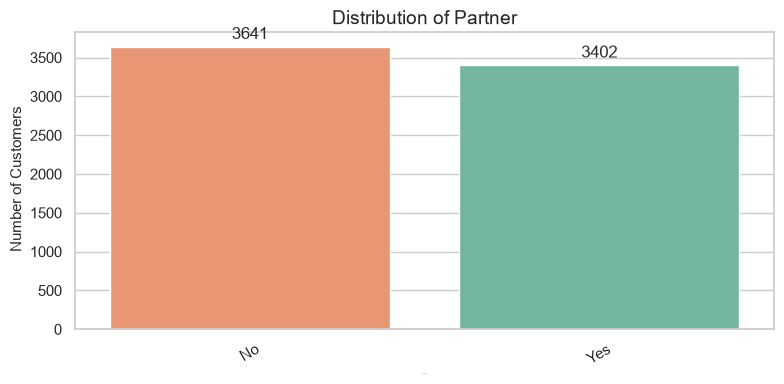

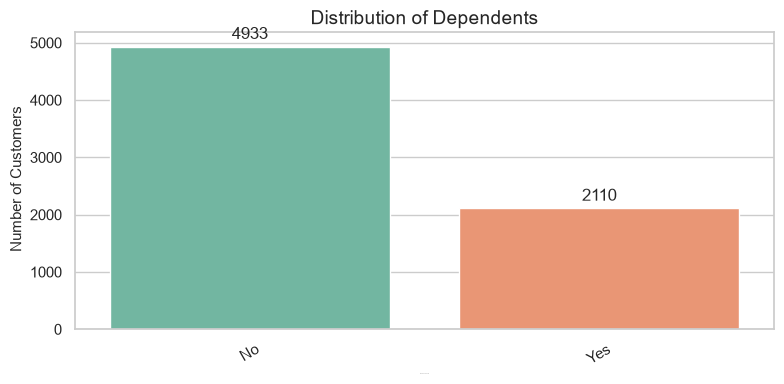

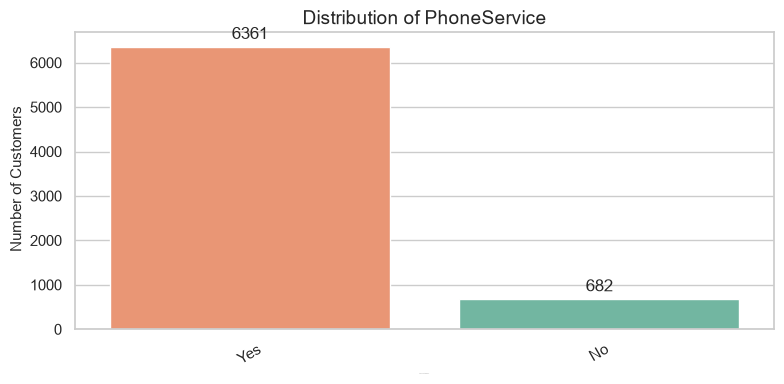

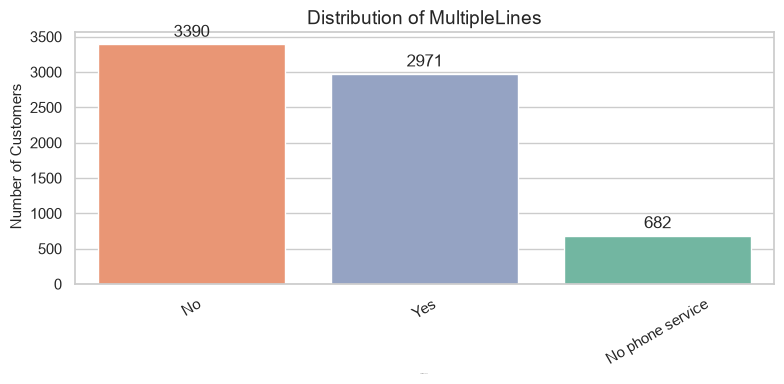

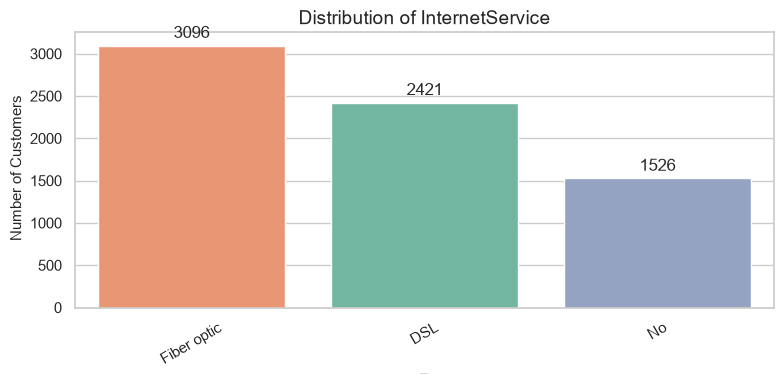

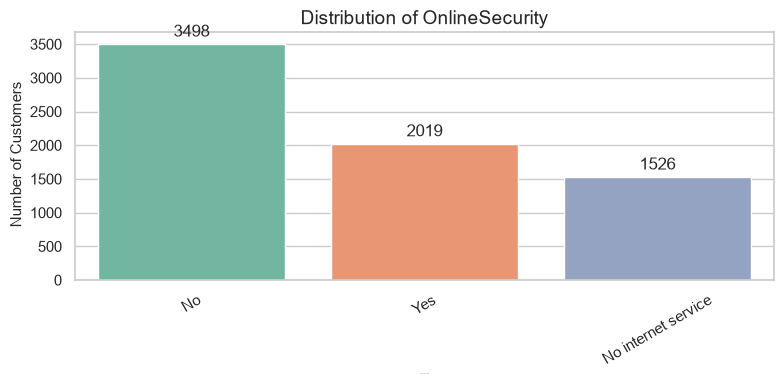

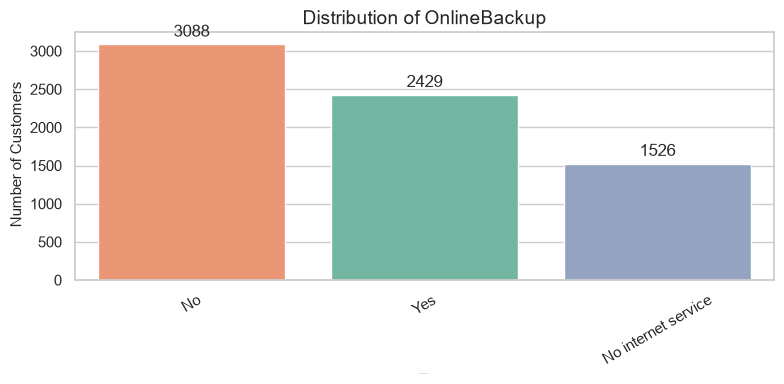

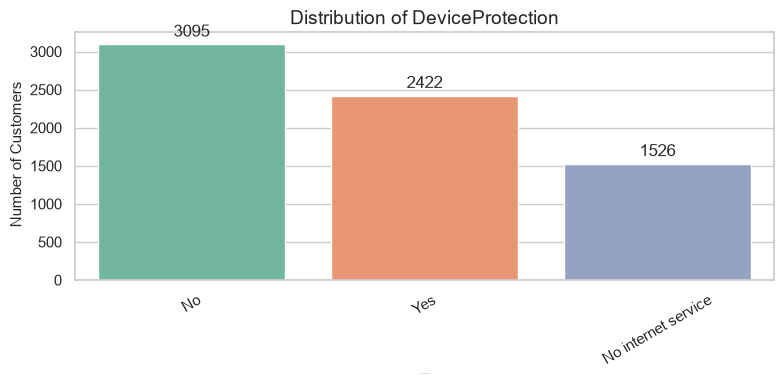

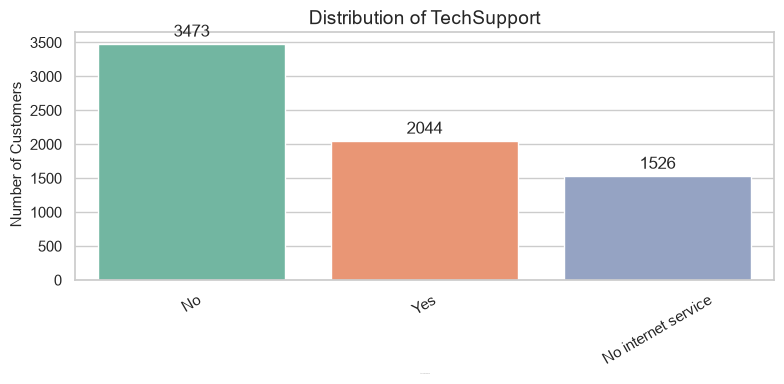

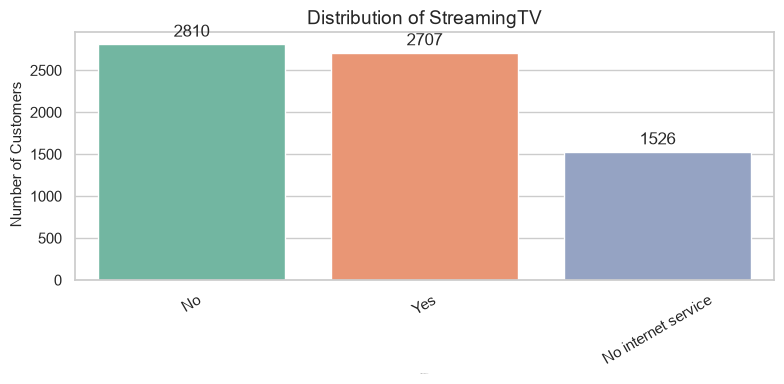

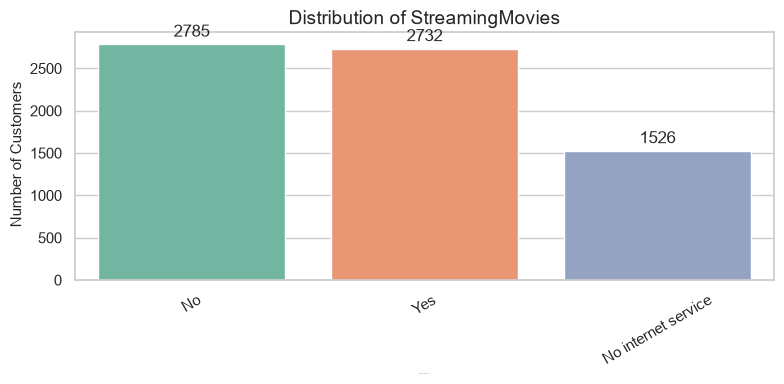

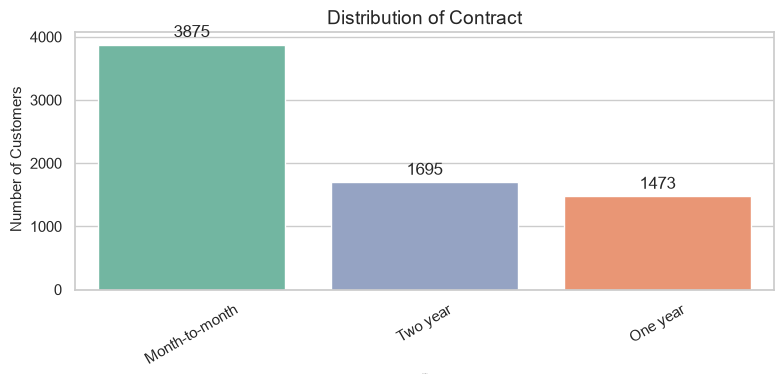

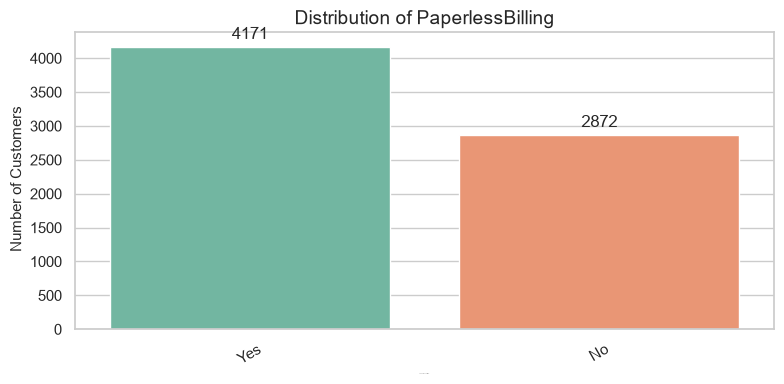

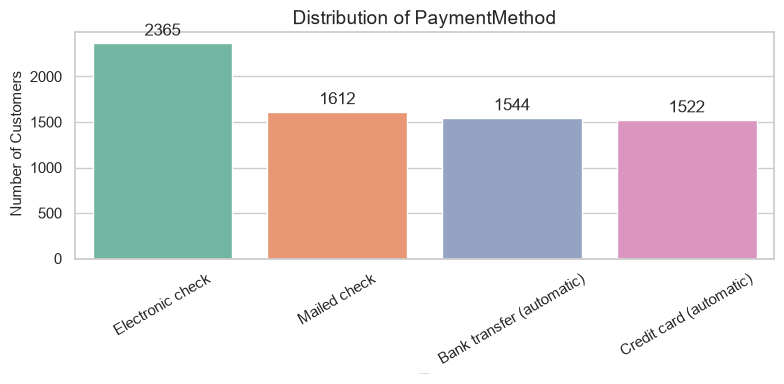

In [53]:
#categorial visualization
#identifying categorical columns, excluding ID
categorical_columns = df.select_dtypes(include = ["object" , "str"]).columns.drop(["customerID", "TotalCharges", "Churn"])
#create count plot bar for each categorical column
for column in categorical_columns:
    plt.figure(figsize=(8,4))

    ax =sns.countplot(
        data = df,
        x = column,
        hue = column,
        palette = "Set2",
        legend = False,
        order = df[column].value_counts().index
    )
    plt.title(f"Distribution of {column}", fontsize = 14)
    plt.xlabel(column, fontsize = 1)
    plt.ylabel(" Number of Customers" , fontsize = 11)
    plt.xticks(rotation = 30)

    for container in ax.containers:
        ax.bar_label(container , padding = 3)
    
    plt.tight_layout()
    plt.show()

Numerical Features : Descriptive Statistics


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


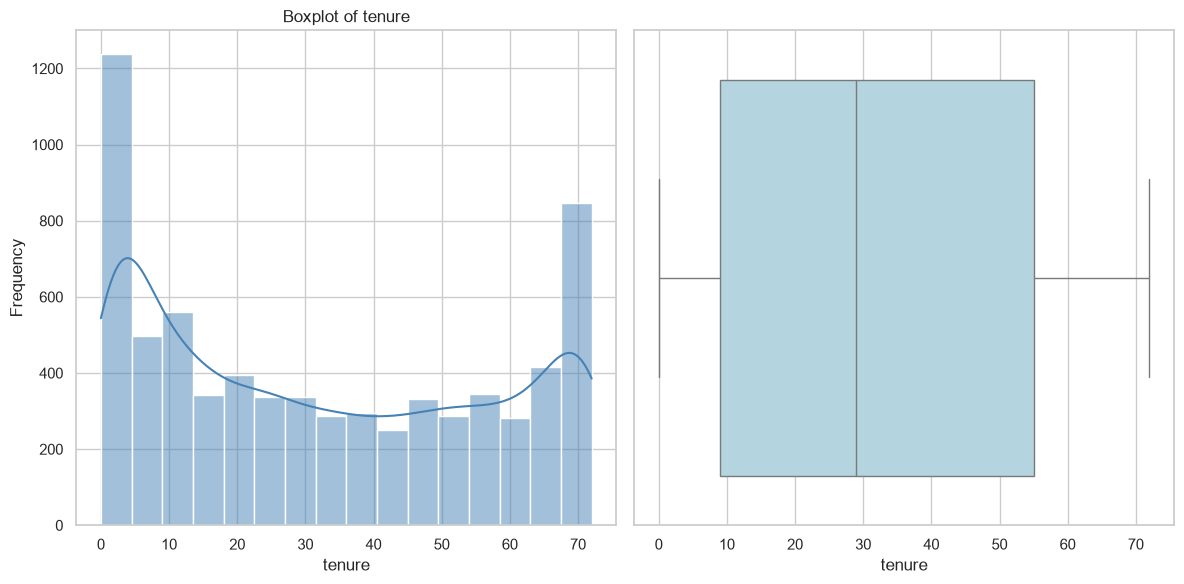

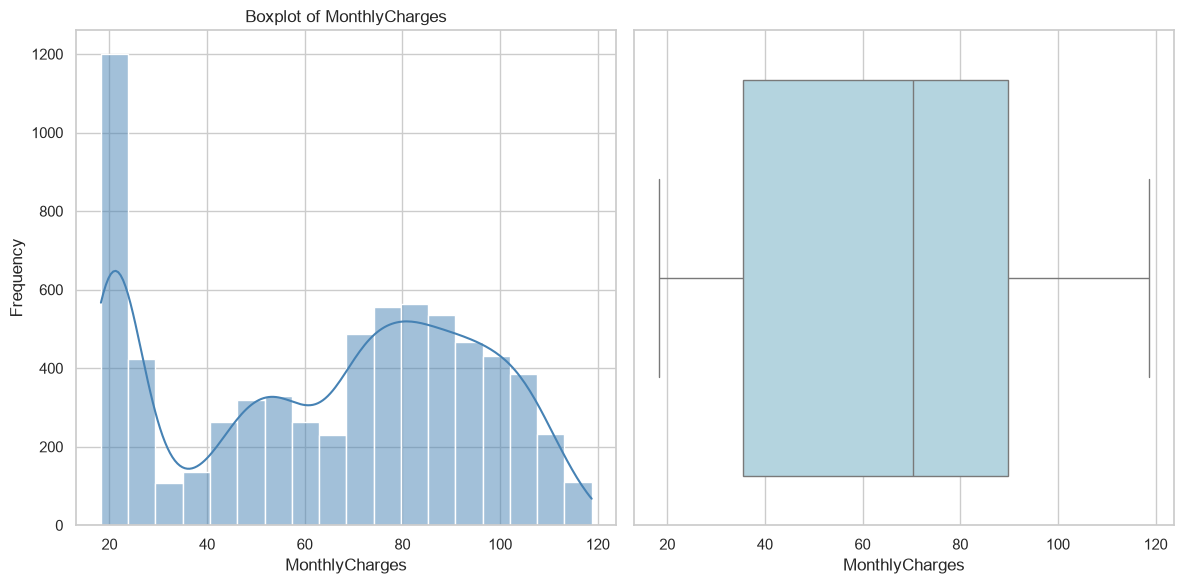

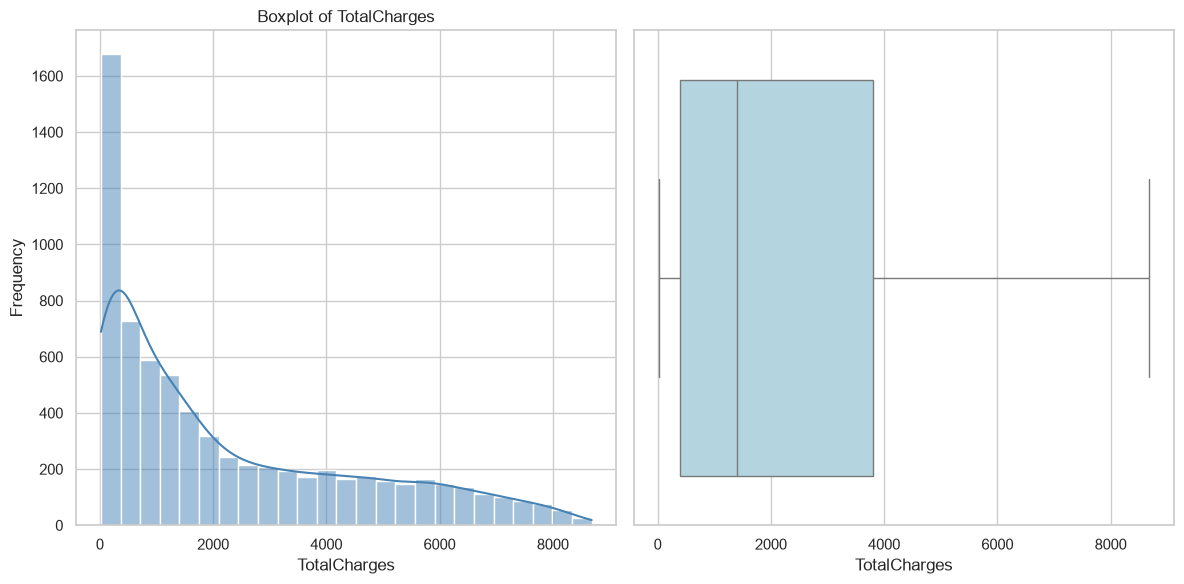

In [54]:
#Identify numerical features

numerical_columns = ["tenure" , "MonthlyCharges" , "TotalCharges"]

#convert TotalCharges to numeric
#errors ='coerce  means Pandas what to do when it encounters a value that cannot be converted? Convert invalid values into NaN.
df ["TotalCharges"] = pd.to_numeric(df["TotalCharges"] , errors = "coerce")

#Display descriptive statistic
print ("Numerical Features : Descriptive Statistics")
display(df[numerical_columns].describe())

#create Histogram and Box plot
for column in numerical_columns:
    fig , axes = plt.subplots(1 , 2, figsize = (12,6))

    #Histogram
    sns.histplot(data = df , x = column , kde = True, ax = axes[0] , color = "steelblue")
    axes[0].set_title(f"Distribution of {column}")
    axes[0].set_xlabel (column)
    axes[0].set_ylabel("Frequency")

    #Box plot
    sns.boxplot(data = df , x = column , ax =axes[1] , color = "lightblue")
    axes[0].set_title(f"Boxplot of {column}")
    axes[1].set_xlabel(column)

    plt.tight_layout()
    plt.show()

In [55]:
#Interpret numerical distributions, skewness, potential outliers.

for column in numerical_columns:
    
    #calculate skewness
    skewness = df[column].skew()

    #calculate quartiles
    Q1 =df[column].quantile(0.25)
    Q3 =df[column].quantile(0.75)
     
    #calculate interquartile range
    IQR =Q3 - Q1

    #Calculate outlier boundries
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    #count potential outliers
    outliers = df [
        (df[column]< lower_bound) | 
        (df[column]> upper_bound)
    ] [column]
    print(f" \n{'=' * 45}")
    print(f"Feature = {column}")
    print (f"{'=' * 45}")
    print(f"Skewness:{skewness:.3f}")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")
    print(f"Numer of Potential Outliers: {len(outliers)}")
    print(f"Outlier Percentage:{len(outliers) / df[column].notna().sum() *100: .2f}%")


 
Feature = tenure
Skewness:0.240
Lower Bound: -60.00
Upper Bound: 124.00
Numer of Potential Outliers: 0
Outlier Percentage: 0.00%
 
Feature = MonthlyCharges
Skewness:-0.221
Lower Bound: -46.02
Upper Bound: 171.38
Numer of Potential Outliers: 0
Outlier Percentage: 0.00%
 
Feature = TotalCharges
Skewness:0.962
Lower Bound: -4688.48
Upper Bound: 8884.67
Numer of Potential Outliers: 0
Outlier Percentage: 0.00%


churn_rate by gender:
gender
Female    26.92
Male      26.16
Name: Churn_binary, dtype: float64
churn_rate by Partner:
Partner
No     32.96
Yes    19.66
Name: Churn_binary, dtype: float64
churn_rate by Dependents:
Dependents
No     31.28
Yes    15.45
Name: Churn_binary, dtype: float64
churn_rate by PhoneService:
PhoneService
Yes    26.71
No     24.93
Name: Churn_binary, dtype: float64
churn_rate by MultipleLines:
MultipleLines
Yes                 28.61
No                  25.04
No phone service    24.93
Name: Churn_binary, dtype: float64
churn_rate by InternetService:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn_binary, dtype: float64
churn_rate by OnlineSecurity:
OnlineSecurity
No                     41.77
Yes                    14.61
No internet service     7.40
Name: Churn_binary, dtype: float64
churn_rate by OnlineBackup:
OnlineBackup
No                     39.93
Yes                    21.53
No internet service     7.40
Name: Churn_bina

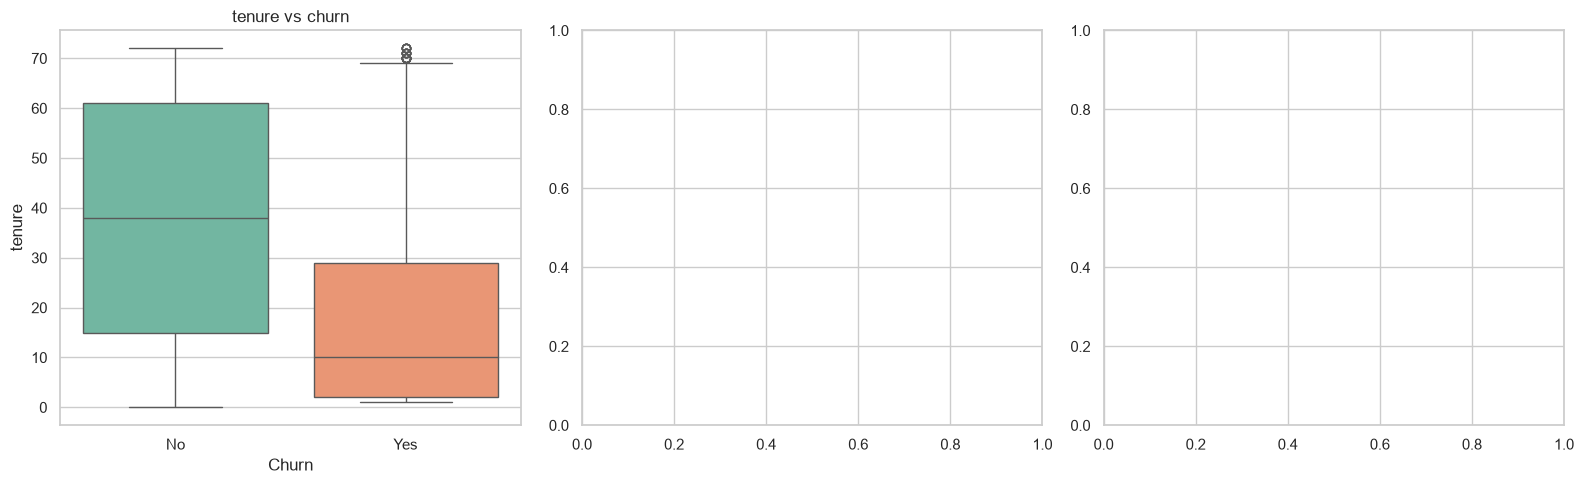

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

In [56]:
# Bivariate Analysis — Relationship with Churn
#features vs Churn

#Convert Churn into binary values to calculate churn rate
df["Churn_binary"] = df["Churn"].map({"No": 0 , "Yes": 1})

#churn rates across categorical features
categorical_columns = df.select_dtypes(include = ["str" , "object"]).columns.drop(["customerID" , "Churn"])

for column in categorical_columns:
    churn_rate = (
        df.groupby(column , observed = True)["Churn_binary"]
        .mean()
        .mul(100)
        .round(2)
    )
    print(f"churn_rate by {column}:")
    print(churn_rate.sort_values(ascending = False))


#Numerical features compared by churn status
numerical_columns = ["tenure", "MonthlyCharges", "TotalCharges"]    
fig , axes = plt.subplots(1 , 3, figsize=(16 , 5))

for i, column in enumerate(numerical_columns):
    sns.boxplot(
        data = df,
        x = "Churn",
        y = column,
        hue ="Churn",
        palette = "Set2",
        legend=False,
        ax = axes[i]
    )

    axes [i].set_title(f"{column} vs churn")
    axes[i].set_xlabel("Churn")
    axes[i].set_ylabel(column)

    plt.tight_layout()
    plt.show()

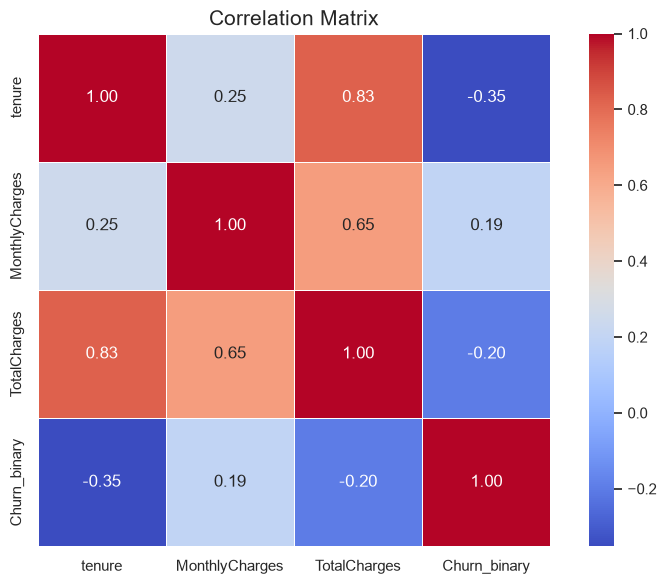

In [57]:
# correlation matrix
correlation_data = df[["tenure", "MonthlyCharges", "TotalCharges", "Churn_binary"]]

#calculaet correlation matrix
correlation_matrix = correlation_data.corr()

#visualize correlation
plt.figure(figsize = ( 8 ,6))
sns.heatmap(
    correlation_matrix,
    annot = True,
    cmap ="coolwarm",
    fmt = ".2f",
    linewidth = 0.5,
    cbar=True,
    square =True
)

plt.title("Correlation Matrix", fontsize = 15)
plt.tight_layout()
plt.show()

## 2.4 Key Findings and Insights

### 1. Target Variable — Customer Churn
- The dataset contains 7,043 customers.
- 5,174 customers (73.46%) did not churn.
- 1,869 customers (26.54%) churned.
- The target variable is moderately imbalanced, since the majority of customers did not leave.

### 2. Categorical Features
- Frequency distributions revealed the most common categories across customer demographics, subscribed services, contract types, and payment methods.
- Churn rates were calculated for each category to identify customer groups with higher churn percentages.
- These patterns will help identify potentially important predictors of customer churn.

### 3. Numerical Features
- Histograms were used to examine the distributions of tenure, MonthlyCharges, and TotalCharges.
- Boxplots were used to identify potential outliers and compare numerical features across churn categories.
- Skewness was considered when examining the distributions.

### 4. Correlation Analysis
- A correlation matrix was generated to investigate linear relationships among numerical features and the binary churn variable.
- Correlation values help identify associations but do not establish causation.

### 5. Data Quality Observations
- `customerID` is an identifier and will not be used as a predictive feature.
- `TotalCharges` required conversion from text to numeric values.
- Missing values resulting from invalid conversions will be investigated during data cleaning.

### Conclusion

EDA provided an initial understanding of customer characteristics, churn distribution, feature relationships, and potential data-quality issues.

The next stage will focus on data cleaning, feature preparation, and preprocessing before training machine-learning models.

# Stage 3: Data Cleaning and Feature Preparation

The objective of this stage is to prepare the dataset for machine learning. Before training a model, we need to ensure that the data is clean, relevant, and represented in a format that machine learning algorithms can understand.

This stage includes handling missing values, checking duplicates, removing irrelevant features, encoding categorical variables, scaling numerical features, and splitting the dataset into training and testing sets.

## 3.1. Handling Missing Values

Missing values can affect the performance of machine learning algorithms. Therefore, we first inspect the dataset for missing observations.

The `TotalCharges` column is initially stored as a text variable, although it represents numerical values. We convert it into a numerical data type using `pd.to_numeric()`.

The parameter `errors="coerce"` converts values that cannot be interpreted as numbers into `NaN` (Not a Number), allowing us to identify and handle them.

After conversion, we inspect the missing values and investigate the affected observations before deciding how to handle them.

## 3.2. Checking and Handling Duplicate Records

Duplicate observations can introduce bias into a model by giving repeated records additional influence during training.

We use `df.duplicated().sum()` to count the number of duplicate rows.

If duplicates are found, we investigate them before removal. In this dataset, `customerID` identifies individual customers, so we should also consider whether repeated customer records are legitimate or accidental.

## 3.3. Removing Irrelevant Features

Not every column in a dataset contributes useful information to a prediction task.

The `customerID` column is an identifier assigned to each customer. It does not describe customer behavior or provide meaningful predictive information about churn.

Therefore, we exclude it from the model features.

We also separate the target variable, `Churn`, from the independent variables. The target represents what we want the model to predict, while the remaining columns contain the information used to make that prediction.

## 3.4. Understanding Categorical Encoding

Machine learning algorithms generally require numerical input. However, several variables in this dataset contain categorical values, such as `Gender`, `Contract`, and `PaymentMethod`.

Categorical encoding converts these categories into numerical representations.

Before choosing an encoding method, it is important to understand the different types of categorical variables.

### A. Nominal Encoding

Nominal variables contain categories without a natural order.

Examples:
- Gender: Male, Female
- InternetService: DSL, Fiber optic, No
- PaymentMethod: Electronic check, Mailed check, Bank transfer, Credit card

**One-Hot Encoding** is commonly used for nominal variables. It creates a separate binary column for each category.

For example, the `InternetService` variable can be represented by three columns:

| InternetService | DSL | Fiber optic | No |
|---|---:|---:|---:|
| DSL | 1 | 0 | 0 |
| Fiber optic | 0 | 1 | 0 |
| No | 0 | 0 | 1 |

This approach avoids assigning an artificial numerical ranking to categories that have no natural order.

### B. Ordinal Encoding

Ordinal variables have categories with a meaningful order.

For example:

| Satisfaction | Encoded value |
|---|---:|
| Low | 1 |
| Medium | 2 |
| High | 3 |

Ordinal encoding preserves the ranking between categories.

However, assigning numerical values can imply relationships between categories that may not accurately represent the data. Therefore, the category order must be defined carefully.

### C. Binary Encoding

Binary categorical variables contain only two possible categories.

For example:

| Partner | Encoded value |
|---|---:|
| No | 0 |
| Yes | 1 |

These variables can be converted into binary numerical values using a mapping.

The target variable `Churn` is also converted into binary values:

- No = 0
- Yes = 1

This makes it possible to train a binary classification model.

### D. High-Cardinality Categorical Variables

Cardinality refers to the number of unique categories in a categorical feature.

A variable with a large number of unique categories is called a high-cardinality variable.

For example, a `City` feature containing 500 different cities has high cardinality.

Applying One-Hot Encoding to such a variable would create 500 additional columns. This can increase dimensionality, computational cost, and the risk of overfitting.

Alternative approaches include:

- **Frequency Encoding:** Replaces each category with its frequency or proportion in the dataset.
- **Grouping Rare Categories:** Combines infrequent categories into a single group.
- **Target Encoding:** Replaces categories with a statistic calculated from the target variable, such as the average churn rate. This requires careful cross-validation to avoid data leakage.
- **Feature Hashing:** Maps categories into a fixed number of numerical features using a hashing function.

In our Telco dataset, `customerID` has high cardinality because almost every customer has a unique identifier. However, it is not a meaningful predictive feature, so we remove it instead of encoding it.

The remaining categorical features have relatively low cardinality. Therefore, One-Hot Encoding is an appropriate choice for this project.

## 3.5. Understanding Feature Scaling

Numerical features can have very different ranges.

For example:
- `tenure`: ranges from 0 to 72 months.
- `MonthlyCharges`: ranges from approximately 18 to 119.
- `TotalCharges`: can reach several thousand.

Some machine learning algorithms, particularly Logistic Regression, use optimization methods that can be affected by differences in feature scales.

**Standardization** transforms numerical features so that they have approximately:

- Mean = 0
- Standard deviation = 1

The formula is:

\[
z = \frac{x-\mu}{\sigma}
\]

Where:
- \(x\) is the original value.
- \(\mu\) is the feature mean.
- \(\sigma\) is the feature standard deviation.
- \(z\) is the standardized value.

We use `StandardScaler` for numerical features.

Tree-based models, such as Decision Trees and Random Forests, generally do not require feature scaling, but using a consistent preprocessing structure makes model comparison easier.

## 3.6. Understanding Data Leakage

Data leakage occurs when information that should not be available during model training influences the training process.

It can produce unrealistically good evaluation results, while the model performs poorly on genuinely unseen data.

For example, if we calculate the mean and standard deviation of the entire dataset before splitting it into training and testing sets, information from the test set influences the preprocessing.

To prevent this, we split the dataset first.

The correct procedure is:

1. Split the dataset into training and testing sets.
2. Fit preprocessing transformations using only the training data.
3. Apply the learned transformations to the test data.
4. Train and evaluate the model.

We can use a `Pipeline` to ensure that preprocessing and model training follow this procedure correctly.

## 3.7. Train-Test Split

The dataset is divided into two subsets:

- **Training set:** Used to train the machine learning model.
- **Testing set:** Used to evaluate the model on observations it has not seen during training.

We use `train_test_split()` from Scikit-learn.

The `stratify` parameter is particularly important in this project because the target variable is imbalanced: approximately 73.46% of customers do not churn, while 26.54% do.

Stratified splitting preserves approximately the same proportion of churn and non-churn observations in both subsets.

## 3.8. Building a Preprocessing Pipeline

Instead of applying transformations separately, Scikit-learn provides two useful tools: `ColumnTransformer` and `Pipeline`.

### ColumnTransformer

`ColumnTransformer` allows us to apply different preprocessing operations to different groups of columns.

For this project:

- Numerical features: missing-value imputation and standardization.
- Categorical features: missing-value imputation and One-Hot Encoding.

### Pipeline

A `Pipeline` connects preprocessing steps and a machine learning estimator into one workflow.

For example:

1. Preprocess the input features.
2. Transform numerical and categorical variables.
3. Pass the transformed data to the classification algorithm.
4. Generate predictions.

The main advantage is that the same preprocessing procedure is applied consistently during training and prediction, while helping prevent data leakage.

## 3.9. Summary

At the end of this stage, the dataset should be ready for machine learning.

The prepared data will have:
- Missing values investigated and handled.
- Duplicate records checked.
- Irrelevant identifiers removed.
- Target and input features separated.
- Categorical variables encoded.
- Numerical variables standardized where appropriate.
- Training and testing sets created.
- Preprocessing organized into a reusable pipeline.

**The next stage is Model Training**, where we will train classification algorithms, beginning with Logistic Regression and Random Forest, and compare their performance in predicting customer churn.

In [58]:
# Inspect missing values in TotalCharges column
df ["TotalCharges"] = pd.to_numeric(df["TotalCharges"] , errors= "coerce")

#check misisng values
print("Missing Vlaues")
display(df.isnull().sum())

missing = df.isnull().sum()
missing = missing[missing > 0]
print(missing)
# now we have realzied that the   missing values is for TotalCharges feature, we can replace them with NaN 
#Inspect rows  with missing TotalCharges
# Inspect rows with missing TotalCharges
display(
    df.loc[df["TotalCharges"].isna(),
           ["tenure", "MonthlyCharges", "TotalCharges"]]
)

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Missing Vlaues


customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
Churn_binary         0
dtype: int64

TotalCharges    11
dtype: int64


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


Duplicate rows: 0


In [59]:
#Handle missing values and remove irrelevant columns

## Fill missing TotalCharges with 0 if they correspond to zero-tenure customers
df["TotalCharges"] = df["TotalCharges"].fillna(0)

#Remove CusotmerId because they are only indetifier
if "customerID" in df.columns:
    df = df.drop(columns = ["customerID"])

#create binary target variable
df["Churn_binary"] = df ["Churn"].map({"No": 0 , "Yes": 1})

#Separe features and Target
X = df.drop(columns = ["Churn" , "Churn_binary"])
y = df["Churn_binary"]
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

Feature Shape: (7043, 19)
Target Shape: (7043,)


In [60]:
#Identify numerical and categorical columns
numerical_features = X.select_dtypes(include = ["int64" , "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include = ["object" , "str"]).columns.tolist()
print("numerical features:" , numerical_features)
print("\n categorical features:" , categorical_features)

numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

 categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [61]:
#Split the data set to traing set and test set

from sklearn.model_selection import train_test_split

X_train , X_test , y_train, y_test = train_test_split(
    X,
    y, 
    test_size =0.2,
    random_state = 42,
    stratify = y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\n Training target distribution:")
print(y_train.value_counts(normalize = True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training set: (5634, 19)
Testing set: (1409, 19)

 Training target distribution:
Churn_binary
0    73.46
1    26.54
Name: proportion, dtype: float64

Testing target distribution:
Churn_binary
0    73.46
1    26.54
Name: proportion, dtype: float64


In [62]:
#Build Preprocessing transformer
# SimpleImputer to handle missing data
#StandardScaler to transfomr numerical data
#OneHotEncoder toencode categorical data
#ColumnTransformer to apply correct transformation to each categorical group
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

#Numerical preprocessing
numerical_transformer = Pipeline(steps = [
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler" , StandardScaler())
])

#categorical Preprocessing
categorical_transformer = Pipeline(steps = [
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown = "ignore"))
])

#combine both processing pipeline
preprocessor = ColumnTransformer(transformers = [
    ("num", numerical_transformer, numerical_features),
    ("cat" , categorical_transformer , categorical_features)
])
print("Preprocessing transformer created successfully.")

Preprocessing transformer created successfully.


In [63]:
#fit transfomrers on training data and transform it
X_train_prepared = preprocessor.fit_transform(X_train)

#transfomr test datausing the same fitted transformation
X_test_prepared = preprocessor.transform(X_test)

print("Prepared training data:", X_train_prepared.shape)
print("Prepared testing data:", X_test_prepared.shape)


Prepared training data: (5634, 45)
Prepared testing data: (1409, 45)


# Stage 4 — Model Training

## 4.1 Introduction

In this stage, we train machine-learning models to predict whether a customer will leave the telecommunications company (Churn = Yes) or remain with it (Churn = No).

We use **supervised learning** because our dataset contains historical customer information together with known churn labels.

The dataset has already been cleaned, transformed, and divided into training and testing subsets:

- **Training set:** Used to teach the algorithms patterns and relationships between customer characteristics and churn.
- **Testing set:** Reserved for evaluating how well the trained models perform on previously unseen data.

We selected three classification algorithms:

1. Logistic Regression
2. Random Forest
3. XGBoost

Using different algorithms allows us to compare different learning strategies and identify which approach is most effective for predicting customer churn.

## 4.2 Selected Machine-Learning Algorithms

### 1. Logistic Regression

Logistic Regression is a supervised classification algorithm commonly used for binary classification problems.

It first calculates a linear combination of input features:

**Linear function:**

z = β₀ + β₁x₁ + β₂x₂ + ⋯ + βₙxₙ

Where:

- x₁, x₂, ..., xₙ represent the input features.
- β₀ is the intercept.
- β₁, β₂, ..., βₙ are the model coefficients.

It then applies the sigmoid function to convert the linear output into a probability:

**Sigmoid function:**

P(y = 1 | X) = 1 / (1 + e⁻ᶻ)

In our project, this probability represents the estimated likelihood that a customer will churn.

The algorithm learns its coefficients by minimizing a loss function, typically Binary Cross-Entropy (Log Loss).

**Binary Cross-Entropy Loss:**

L = −(1/N) Σᵢ₌₁ᴺ [yᵢ log(pᵢ) + (1 − yᵢ) log(1 − pᵢ)]

Where:

- N is the number of observations.
- yᵢ is the actual class label.
- pᵢ is the predicted probability of class 1.
- log represents the natural logarithm.

**Why use it?**

- Provides a simple baseline model.
- Computationally efficient.
- Allows us to interpret the relationship between features and predicted churn probabilities.
- Uses optimization algorithms such as L-BFGS to estimate its coefficients.

### 2. Random Forest

Random Forest is an ensemble learning algorithm based on **Bagging (Bootstrap Aggregating)**.

It constructs multiple decision trees using different bootstrap samples of the training data. Each tree also considers randomly selected subsets of features when determining splits.

For classification, the final prediction is determined by majority voting among the trees.

Decision trees commonly use impurity measures such as Gini impurity or Entropy to select their splits.

**Gini Impurity:**

Gini = 1 − Σₖ₌₁ᴷ pₖ²

**Entropy:**

H = −Σₖ₌₁ᴷ pₖ log₂(pₖ)

Where:

- K is the number of classes.
- pₖ represents the proportion of observations belonging to class k.

Both measures quantify the impurity of a decision-tree node. A lower impurity indicates that the observations in the node are more concentrated in one class.

**Why use it?**

- Captures nonlinear relationships.
- Identifies interactions between customer features.
- Reduces the variance of individual decision trees.
- Provides feature-importance estimates.

### 3. XGBoost

XGBoost (Extreme Gradient Boosting) is an optimized implementation of gradient-boosted decision trees.

Unlike Random Forest, which builds trees independently, XGBoost builds trees sequentially. Each new tree attempts to improve the predictions made by the existing ensemble.

It uses gradient-based optimization and second-order information (Hessian) to improve the objective function.

A simplified boosting update is:

**Boosting update:**

Fₘ(x) = Fₘ₋₁(x) + ηhₘ(x)

Where:

- Fₘ(x) is the updated prediction.
- Fₘ₋₁(x) is the previous ensemble prediction.
- hₘ(x) is the newly added decision tree.
- η is the learning rate, which controls the contribution of each new tree.

**Why use it?**

- Captures complex nonlinear patterns.
- Uses gradient and Hessian information during optimization.
- Includes regularization to control model complexity.
- Often achieves strong predictive performance on structured/tabular datasets.

## 4.3 Training Strategy

We train all three algorithms using the same training and testing split and the same preprocessing strategy.

We use Scikit-learn's `Pipeline` to combine preprocessing and model training.

Each pipeline performs the following operations:

1. Applies the numerical and categorical transformations.
2. Fits the classification algorithm on the transformed training data.
3. Produces predictions for new observations using the learned transformations and model.

This approach ensures that preprocessing is fitted on the training data rather than independently on the test data, helping prevent data leakage.

We also set `random_state=42` where applicable to improve reproducibility.

## 4.4 Objective

The main objective of this stage is to fit three different classification models and prepare them for evaluation.

In the next stage, we will compare their predictive performance using several evaluation metrics, including:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix

Because our dataset is imbalanced, with approximately 73.46% non-churning customers and 26.54% churning customers, accuracy alone will not be sufficient to determine the best model.

We will pay particular attention to Recall and F1-score for the Churn class, since identifying customers who are likely to leave is an important objective of this project.

In [68]:
# Import classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

#Define models
models = {
    "Logistic regression":LogisticRegression(
        solver = "lbfgs",
        max_iter = 1000,
        random_state = 42
    ),

    "Random Forest":RandomForestClassifier(
        n_estimators = 200,
        random_state = 42,
        n_jobs = -1 #use all avaiable core to parallely train trees
    ),

    "XGBoost":XGBClassifier(
        n_estimators = 200,
        learning_rate = 0.05,
        max_depth = 4,
        subsample =0.8,
        colsample_bytree = 0.8,
        eval_metric = "logloss",
        random_state = 42,
        n_jobs = -1
    )
}

#cretae Pipelines
pipelines = {
    name : Pipeline( steps = [
        ("preprocessor" , preprocessor),
        ("classifier" , model) 
    ])
     for name , model in models.items()
}

for name , pipeline in pipelines.items():
    pipeline.fit(X_train , y_train)
    print(f"{name}: training completed.")



Logistic regression: training completed.
Random Forest: training completed.
XGBoost: training completed.


# Stage 5 — Model Evaluation and Comparison

## 5.1 Introduction

After training Logistic Regression, Random Forest, and XGBoost, the next step is to evaluate their predictive performance.

A model that performs well on training data does not necessarily generalize to new, unseen data. Therefore, we evaluate the trained models using the **test dataset**, which was not used during model training.

The main objectives of this stage are:

- Measure the predictive performance of each model.
- Evaluate how accurately the models identify customers who churn.
- Compare the strengths and weaknesses of the three algorithms.
- Select the most suitable model for customer churn prediction.

## 5.2 Evaluation Metrics

Since this dataset is imbalanced (approximately 73.46% non-churn customers and 26.54% churn customers), accuracy alone is not sufficient for evaluating model performance.

We use several complementary classification metrics.

### 1. Accuracy

Accuracy measures the proportion of all predictions that are correct.

Accuracy = (TP + TN) / (TP + TN + FP + FN)

A high accuracy score does not necessarily indicate good churn detection, because a model may perform well simply by predicting the majority class.

### 2. Precision

Precision measures the proportion of customers predicted to churn who actually churned.

Precision = TP / (TP + FP)

High precision means fewer non-churning customers are incorrectly classified as potential churners.

### 3. Recall

Recall measures the proportion of actual churners correctly identified by the model.

Recall = TP / (TP + FN)

High recall is particularly important in customer churn prediction because it helps identify more customers who are likely to leave.

4. F1-Score

The F1-score is the harmonic mean of precision and recall.

F1 = 2 × (Precision × Recall) / (Precision + Recall)

It provides a balance between precision and recall and is useful when working with imbalanced datasets.

5. ROC-AUC

The Area Under the Receiver Operating Characteristic Curve (ROC-AUC) measures how well a model distinguishes between the two classes across different classification thresholds.

AUC = 1.0: Perfect class separation.

AUC = 0.5: Performance equivalent to random ranking.

AUC below 0.5: Worse than random ranking.

A higher ROC-AUC generally indicates better discrimination between churn and non-churn customers.

5.3 Confusion Matrix

A confusion matrix provides a detailed breakdown of the model's predictions.

It contains four outcomes:

True Positive (TP): A customer churns and the model correctly predicts churn.

True Negative (TN): A customer does not churn and the model correctly predicts non-churn.

False Positive (FP): A customer does not churn, but the model predicts churn.

False Negative (FN): A customer churns, but the model predicts non-churn.

In this project, false negatives are particularly important because they represent customers who actually leave but were not identified by the model.

5.4 Model Comparison

We evaluate all three trained models using the same test dataset:

Logistic Regression

Random Forest

XGBoost

The evaluation results are collected in a comparison table containing Accuracy, Precision, Recall, F1-score, and ROC-AUC.

Comparing these metrics helps us understand the trade-offs between the models rather than relying on a single performance measure.

5.5 Final Model Selection

The final model will be selected based on its overall performance and suitability for customer churn prediction.

In particular, we will consider:

Recall: How effectively the model identifies customers who are likely to churn.

Precision: How reliable its churn predictions are.

F1-score: The balance between precision and recall.

ROC-AUC: Its ability to distinguish between churn and non-churn customers.

The best model is not necessarily the one with the highest accuracy. The final choice should reflect the practical objective of identifying customers at risk of leaving while maintaining an acceptable level of false predictions.

In [75]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

#evaluate all trained models
results = []
for name , pipeline in pipelines.items():
    #predict class labels and probabilities
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[: , 1]

    #calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test , y_pred),
        "Precision": precision_score(y_test , y_pred),
        "Recall": recall_score(y_test , y_pred),
        "F1_Score": f1_score(y_test , y_pred),
        "ROC_AUC": roc_auc_score(y_test , y_prob),
    })





#create comparision table
results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)

,Accuracy,Precision,Recall,F1_Score,ROC_AUC
Model,,,,,
Logistic regression,0.8055,0.6572,0.5588,0.6040,0.8421
Random Forest,0.7835,0.6186,0.4813,0.5414,0.8206
XGBoost,0.8062,0.6712,0.5294,0.5919,0.8457


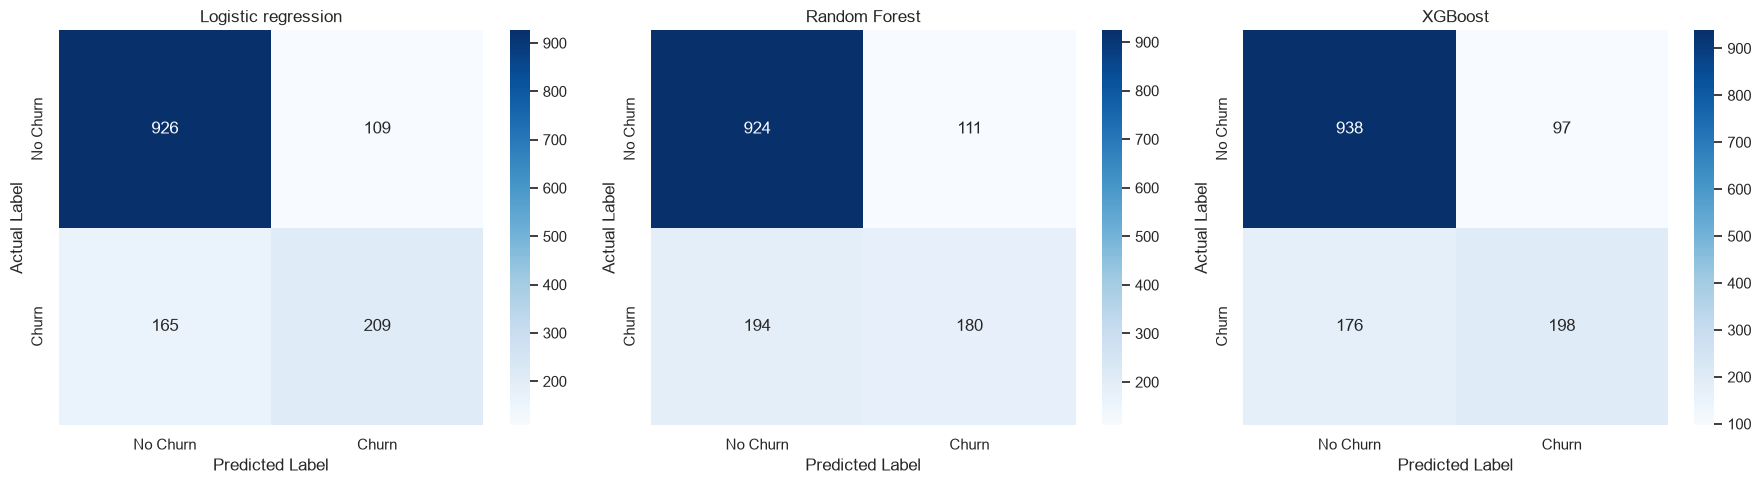

In [83]:
#Confusion Matrices
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

#plot confusion matrices for all models
fig , axes = plt.subplots(1 , 3, figsize= (18 , 5))

for ax , (name , pipeline) in zip (axes , pipelines.items()):
    y_pred = pipeline.predict(X_test)
    cm = confusion_matrix(y_test , y_pred)
    sns.heatmap(
        cm , 
        annot = True,
        fmt = "d",
        cmap ="Blues",
        xticklabels = ["No Churn" , "Churn"],
        yticklabels =["No Churn" , "Churn"],
        ax = ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")
plt.tight_layout()
plt.show()    

In [90]:
#Classification Report nad Model Comparison
from sklearn.metrics import classification_report

for name , pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)

    print(f"\n {'=' * 50} ")
    print(name)
    print("=" * 50)

    print ( classification_report(
        y_test,
        y_pred,
        target_names = ["No Churn" , "Churn"]
    )
    )



Logistic regression
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


Random Forest
              precision    recall  f1-score   support

    No Churn       0.83      0.89      0.86      1035
       Churn       0.62      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409


XGBoost
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.53      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      

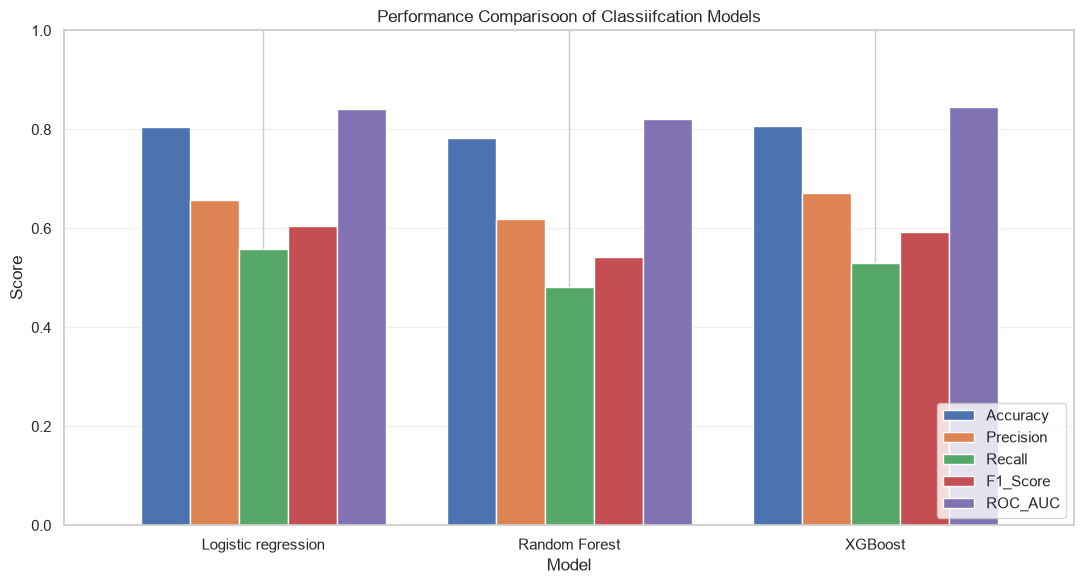

In [94]:
#Visuale comparision of models
metrics =["Accuracy" , "Precision" , "Recall" , "F1_Score" , "ROC_AUC"]
results_df[metrics].plot(
    kind ="bar",
    figsize = (11 , 6),
    ylim =(0,1),
    width = 0.8
)

plt.title("Performance Comparisoon of Classiifcation Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation = 0)
plt.legend(loc = "lower right")
plt.grid(axis = "y" , alpha =0.3)
plt.tight_layout()
plt.show()

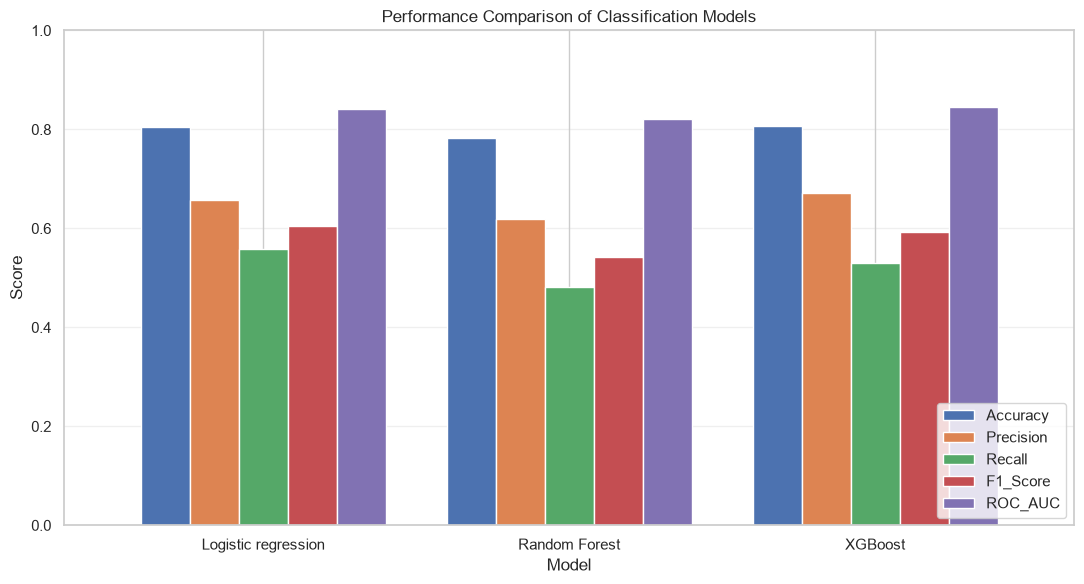

In [ ]:
# Final Model Selection and Interpretation.


In [ ]:
#Final Model Selection and Iterpretation
ranked_models = results_df.sort_values(
    by = "F1_Score",
    ascending =False
)
display(ranked_models.round(4))

#Identify the best model based on F1 Score
best_model_name = ranked_models["F1_Score"].idxmax()
print("best model based on F1_Score:" , best_model_name)

,Accuracy,Precision,Recall,F1_Score,ROC_AUC
Model,,,,,
Logistic regression,0.8055,0.6572,0.5588,0.6040,0.8421
XGBoost,0.8062,0.6712,0.5294,0.5919,0.8457
Random Forest,0.7835,0.6186,0.4813,0.5414,0.8206


Best model based on F1-score: Logistic regression


,Accuracy,Precision,Recall,F1_Score,ROC_AUC
Model,,,,,
Logistic regression,0.8055,0.6572,0.5588,0.6040,0.8421
XGBoost,0.8062,0.6712,0.5294,0.5919,0.8457
Random Forest,0.7835,0.6186,0.4813,0.5414,0.8206


best model based on F1_Score: Logistic regression


# Stage 7 — Interpretation & Final Project

## 7.1 Introduction

After completing data exploration, preprocessing, model training, and evaluation, the final stage focuses on interpreting the results and presenting the findings.

The objective is to understand which customer characteristics are associated with churn, interpret the behavior of the selected machine learning model, and translate the predictive results into meaningful business insights.

This stage also includes documenting the methodology, results, limitations, and conclusions to prepare the project for publication on GitHub.

## 7.2 Feature Importance

Feature importance helps identify which input variables contribute most to a model's predictions.

In this project, we examine the contribution of customer characteristics such as:

- Tenure
- Contract type
- Monthly charges
- Total charges
- Internet service
- Payment method
- Technical support
- Online security

Different algorithms provide different approaches to feature interpretation:

- **Logistic Regression:** Uses model coefficients to indicate the direction and strength of associations with the predicted log-odds of churn.
- **Random Forest:** Uses tree-based feature importance to measure the contribution of features to reductions in impurity.
- **XGBoost:** Provides feature importance measures based on criteria such as gain, weight, and cover.

The interpretation method depends on the selected model.

Feature importance helps identify influential predictors, but it does not establish causal relationships.

## 7.3 Model Interpretation

Model interpretation focuses on understanding how customer characteristics influence the model's predictions.

For example, we investigate whether:

Customers with shorter tenure are more likely to churn.

Month-to-month contracts are associated with higher churn.

Higher monthly charges are associated with customer okdepartures.

Customers without technical support or online security have different churn patterns.

Payment methods are associated with differences in churn behavior.

These relationships are examined using the model's interpretation results and the patterns identified during exploratory data analysis.

It is important to distinguish statistical associations from causal relationships. A feature associated with churn does not necessarily cause customers to leave.

7.4 Business Insights and Recommendations

The purpose of churn prediction is not only to identify customers at risk but also to help businesses develop customer retention strategies.

Based on the model's findings, potential recommendations may include:

Offering retention incentives to customers identified as having a high risk of churn.

Encouraging long-term contracts where appropriate.

Improving technical support and customer service.

Reviewing pricing strategies for customers with high monthly charges.

Developing targeted retention campaigns based on customer characteristics.

Recommendations should be based on the actual findings of the analysis rather than assumptions.

7.5 Project Limitations

Despite the predictive capabilities of machine learning models, this project has several limitations:

The analysis uses a single historical dataset.

The dataset may not represent current customer behavior.

Class imbalance can affect model performance.

Model performance depends on the selected features, preprocessing methods, and hyperparameters.

Predictive relationships do not establish causality.

The default classification threshold may not be optimal for business decisions.

Model performance on unseen real-world data may differ from the test-set results.

These limitations should be considered when interpreting and applying the results.

7.6 Final Conclusions

The final conclusions summarize the main findings of the project, including:

The characteristics and distribution of the dataset.

Important patterns discovered during exploratory data analysis.

Data cleaning and preprocessing decisions.

The performance comparison of Logistic Regression, Random Forest, and XGBoost.

The selected model and the reasons for its selection.

The most influential predictors of customer churn.

Potential business applications and recommendations.

The final model should be selected based on the project's objectives and the trade-off between precision, recall, F1-score, and ROC-AUC rather than accuracy alone.

7.7 GitHub Documentation

The final step is to organize and document the project for reproducibility and presentation.

The GitHub repository should contain:

The Jupyter Notebook with the complete analysis.

A README file describing the project, dataset, methodology, results, and conclusions.

A requirements.txt file listing the required Python libraries.

Relevant visualizations and evaluation results.

Clear instructions for reproducing the analysis.

The objective is to present a complete, reproducible machine learning workflow, from raw data inspection to model interpretation and final conclusions.

In [98]:
best_model_name = results_df["F1_Score"].idxmax()
best_pipeline = pipelines[best_model_name]

print("Selected model:", best_model_name)
print("F1-score:", round(results_df.loc[best_model_name, "F1_Score"], 4))

Selected model: Logistic regression
F1-score: 0.604


In [99]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

,Feature,Importance,Absolute_Importance
1,num__tenure,-1.2575,1.2575
38,cat__Contract_Two year,-0.7766,0.7766
15,cat__InternetService_DSL,-0.6486,0.6486
16,cat__InternetService_Fiber optic,0.6342,0.6342
2,num__MonthlyCharges,-0.5919,0.5919
36,cat__Contract_Month-to-month,0.5829,0.5829
3,num__TotalCharges,0.5363,0.5363
39,cat__PaperlessBilling_No,-0.3432,0.3432
25,cat__DeviceProtection_No internet service,-0.3001,0.3001
17,cat__InternetService_No,-0.3001,0.3001


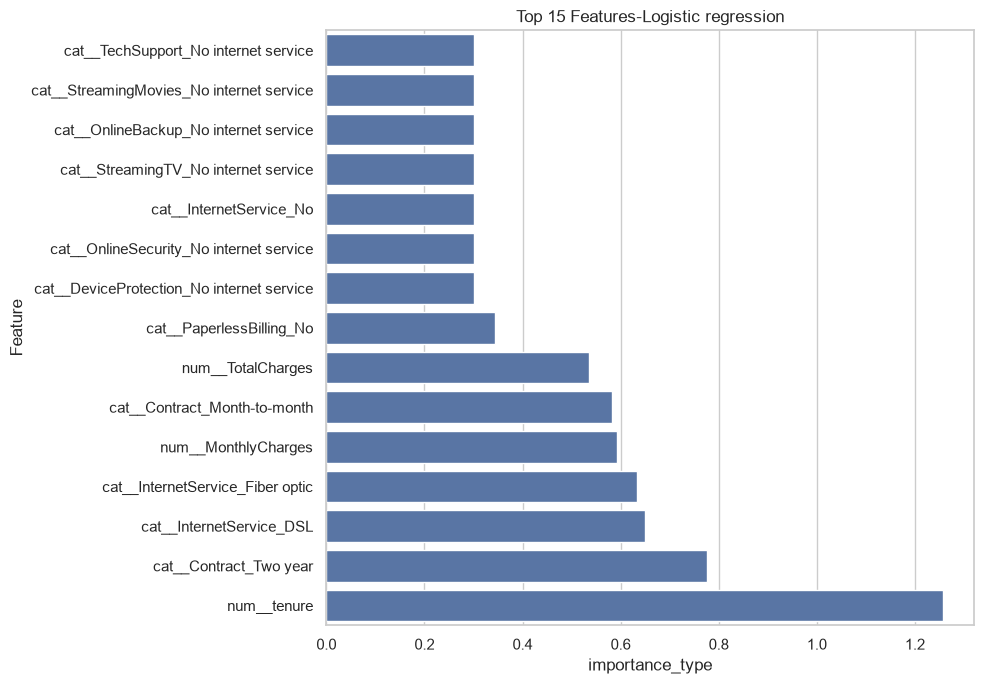

In [115]:
#extract the fitted classifier
classifier = best_pipeline.named_steps["classifier"]

#get feature names after preprocessing
feature_names = best_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

#extract feature importance or coefficients
if hasattr (classifier , "feature_importance"):
    importance_values = classifier.feature_importances_
    importance_type = "Feature Importance"

elif hasattr(classifier , "coef_"):
    importance_values = classifier.coef_[0]
    importance_type = "Absolute Coefficient"
else:
    raise ValueError ("This model does not provide build-in feature importance.")



#cretae feature importance data frame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance" : importance_values
})

importance_df["Absolute_Importance"] = importance_df["Importance"].abs()

importance_df = importance_df.sort_values(
    by = "Absolute_Importance",
    ascending = False
)

#Display the top 15 features
display(importance_df.head(15).round(4))

#visualize the top 15 features
top_features = importance_df.head(15).sort_values(
    by ="Absolute_Importance"
)

plt.figure(figsize = (10,7))

sns.barplot(
    data = top_features,
    x="Absolute_Importance",
    y = "Feature"
)
plt.title(f"Top 15 Features-{best_model_name}")
plt.xlabel("importance_type")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [116]:

# Display the signed coefficients of the top 15 features

display(
    importance_df[
        ["Feature", "Importance", "Absolute_Importance"]
    ].head(15).round(4)
)


,Feature,Importance,Absolute_Importance
1,num__tenure,-1.2575,1.2575
38,cat__Contract_Two year,-0.7766,0.7766
15,cat__InternetService_DSL,-0.6486,0.6486
16,cat__InternetService_Fiber optic,0.6342,0.6342
2,num__MonthlyCharges,-0.5919,0.5919
36,cat__Contract_Month-to-month,0.5829,0.5829
3,num__TotalCharges,0.5363,0.5363
39,cat__PaperlessBilling_No,-0.3432,0.3432
25,cat__DeviceProtection_No internet service,-0.3001,0.3001
17,cat__InternetService_No,-0.3001,0.3001


### 7.3 Model Interpretation — Key Findings

The Logistic Regression model was selected for interpretation based on its F1-score performance.

The analysis of its coefficients revealed several important relationships between customer characteristics and predicted churn.

**1. Customer Tenure**

Tenure had the largest absolute coefficient (-1.2575), indicating a strong negative association with predicted churn. Customers with longer relationships with the company tend to have lower predicted odds of leaving.

**2. Contract Type**

Contract type was among the most influential categorical features.

- Month-to-month contracts had a positive coefficient (+0.5829), indicating higher predicted churn odds.
- Two-year contracts had a negative coefficient (-0.7766), indicating lower predicted churn odds.

This suggests that customers with longer-term contracts are generally less likely to churn according to the model.

**3. Internet Service**

Fiber optic service had a positive coefficient (+0.6342), whereas DSL service had a negative coefficient (-0.6486).

This indicates that internet service type contributes to the model's ability to distinguish between customers who churn and those who remain.

**4. Billing and Charges**

Monthly charges had a negative coefficient (-0.5919), while total charges had a positive coefficient (+0.5363).

These coefficients represent conditional relationships within the multivariable model. Since tenure, monthly charges, and total charges may be correlated, their individual coefficients should be interpreted cautiously.

**5. Other Service Features**

The category "No internet service" had negative coefficients across several service-related variables, suggesting an association with lower predicted churn odds in this model.

### Summary

Customer tenure and contract type were among the most influential predictors of churn in the Logistic Regression model. Internet service type and billing-related variables also contributed to the predictions.

These findings suggest that customer retention strategies could benefit from paying particular attention to customers with short tenure and month-to-month contracts.

However, these results describe predictive associations rather than causal relationships.

### 7.4 Business Insights and Recommendations

Based on the exploratory data analysis and Logistic Regression interpretation, several potential customer retention strategies can be proposed.

**1. Focus on Month-to-Month Customers**

Customers with month-to-month contracts showed higher predicted churn odds.

Recommendation:
- Offer incentives for customers to switch to longer-term contracts.
- Introduce discounts or loyalty benefits for customers who commit to longer contracts.

**2. Improve Early Customer Retention**

Tenure was the strongest predictor in the Logistic Regression model, with a negative coefficient.

Recommendation:
- Develop onboarding programs for new customers.
- Monitor customer satisfaction during the first months of service.
- Offer targeted support to customers with short tenure.

**3. Investigate Fiber Optic Customer Churn**

Fiber optic service had a positive coefficient in the selected model.

Recommendation:
- Investigate customer satisfaction with fiber optic services.
- Examine service reliability, pricing, and technical support.
- Identify potential service-quality issues among fiber optic customers.

**4. Review Pricing and Billing Strategies**

Monthly charges and total charges showed different coefficient directions.

Recommendation:
- Investigate whether pricing levels influence customer satisfaction.
- Review billing transparency and unexpected charges.
- Analyze pricing patterns together with contract type and tenure.

**5. Strengthen Customer Support**

Technical support and other service-related variables appeared among the influential predictors.

Recommendation:
- Improve access to technical assistance.
- Monitor customer complaints and unresolved service issues.
- Evaluate whether additional support services improve retention.

### Summary of Recommendations

The analysis suggests that customer retention strategies should prioritize customers with short tenure, month-to-month contracts, and potentially higher-risk service profiles.

These recommendations are hypotheses based on predictive associations. Their actual effectiveness should be tested through customer feedback, controlled retention experiments, and further business analysis.

### 7.5 Final Conclusions

This project developed a machine learning approach to predict customer churn using the Telco Customer Churn dataset.

The analysis followed a complete machine learning workflow, including data understanding, exploratory data analysis, data cleaning, feature preprocessing, model training, evaluation, and interpretation.

**1. Data Understanding and Exploration**

The dataset contained 7,043 customer records and 21 original columns. Exploratory Data Analysis revealed that approximately 26.54% of customers had churned, indicating an imbalanced classification problem.

**2. Data Cleaning and Preprocessing**

The preprocessing stage included:
- Converting TotalCharges into a numerical variable.
- Handling missing values.
- Removing the customerID identifier.
- Creating a binary target variable.
- Applying One-Hot Encoding to categorical features.
- Applying StandardScaler to numerical features.
- Splitting the dataset into stratified training and testing sets.

**3. Model Development**

Three classification algorithms were trained and evaluated:

- Logistic Regression
- Random Forest
- XGBoost

Each model was implemented using a preprocessing and classification pipeline.

**4. Model Evaluation**

The models were evaluated using Accuracy, Precision, Recall, F1-score, ROC-AUC, confusion matrices, and classification reports.

Logistic Regression achieved the highest F1-score among the evaluated models and was selected for further interpretation.

**5. Model Interpretation**

The Logistic Regression coefficients highlighted several influential predictors:

- Customer tenure had the strongest negative coefficient.
- Month-to-month contracts were associated with higher predicted churn odds.
- Two-year contracts were associated with lower predicted churn odds.
- Internet service type also contributed to churn predictions.

These findings provide insights into customer characteristics associated with churn.

**6. Business Implications**

The results suggest that telecommunications companies could improve retention by focusing on customers with shorter tenure, reviewing month-to-month contract strategies, investigating service satisfaction, and improving customer support.

**7. Limitations and Future Improvements**

Potential improvements include:

- Hyperparameter tuning using GridSearchCV or RandomizedSearchCV.
- Cross-validation for more robust model evaluation.
- Investigating class imbalance using class weights or resampling techniques.
- Optimizing the classification threshold according to business objectives.
- Applying SHAP for more detailed model explanations.
- Testing the model on additional or more recent customer data.

**Final Conclusion**

This project demonstrates how machine learning and statistical analysis can be combined to investigate customer churn and support data-driven retention strategies.

It also provides practical experience with the complete supervised machine learning workflow, from raw data preparation to model evaluation and interpretation.